# LAB 06 - Bài 22: Attention matrix

Trực quan hóa attention matrix mẫu trong tài liệu. Mỗi hàng là token đang được xét; mỗi cột là token mà hàng đó attention tới.

Attention matrix (row sums): [1. 1. 1.]


,I,like,cats
I,0.6,0.2,0.2
like,0.1,0.7,0.2
cats,0.1,0.3,0.6


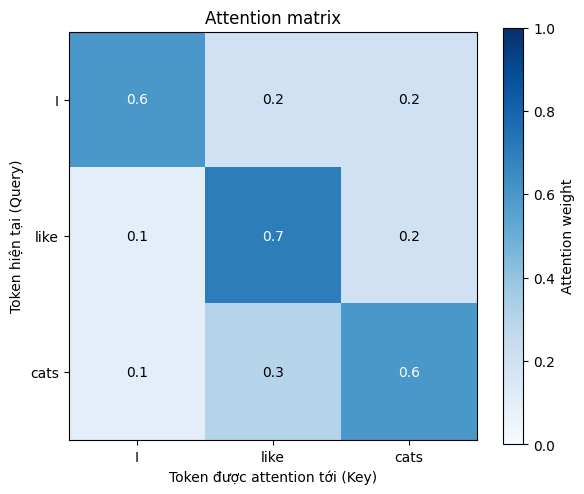

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Attention matrix example from the lab handout
tokens = ["I", "like", "cats"]
attention_matrix = np.array([
    [0.6, 0.2, 0.2],  # I attends to I, like, cats
    [0.1, 0.7, 0.2],  # like attends to I, like, cats
    [0.1, 0.3, 0.6],  # cats attends to I, like, cats
], dtype=float)

# Check matrix dimensions and that each attention row sums to 1
assert attention_matrix.shape == (len(tokens), len(tokens))
assert np.allclose(attention_matrix.sum(axis=1), 1.0)

print("Attention matrix (row sums):", attention_matrix.sum(axis=1))
display(pd.DataFrame(attention_matrix, index=tokens, columns=tokens).round(2))

# Heatmap: rows are the current/query tokens; columns are attended-to tokens
fig, ax = plt.subplots(figsize=(6, 5))
image = ax.imshow(attention_matrix, cmap="Blues", vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(tokens)), labels=tokens)
ax.set_yticks(range(len(tokens)), labels=tokens)
ax.set_xlabel("Token được attention tới (Key)")
ax.set_ylabel("Token hiện tại (Query)")
ax.set_title("Attention matrix")

# Show each matrix value in its heatmap cell
for row in range(attention_matrix.shape[0]):
    for col in range(attention_matrix.shape[1]):
        value = attention_matrix[row, col]
        text_color = "white" if value >= 0.5 else "black"
        ax.text(col, row, f"{value:.1f}", ha="center", va="center", color=text_color)

fig.colorbar(image, ax=ax, label="Attention weight")
fig.tight_layout()
plt.show()